# 01. Preparación de datos

En este proyecto analizo transacciones de PaySim para identificar fraude. Primero revisé la calidad de los datos, preparé las variables y separé los periodos de entrenamiento, validación y evaluación.

La consigna fija el corte en el step 400: hasta allí se trabaja con datos de referencia y desde 401 se simula producción. Como uso saldos finales, el análisis corresponde al momento posterior a la transacción. Cada step representa una hora de simulación.

In [1]:
from pathlib import Path
import sys, os, json, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from IPython.display import display, Markdown
from dotenv import load_dotenv

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/fraud/schema.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
load_dotenv(ROOT / '.env', override=False)
from src.fraud.prepare import prepare, sha256
from src.fraud.schema import FEATURES, PARTITIONS, TARGET, temporal_folds
from src.fraud.tracking import configuration_status, log_preparation

csv_setting = os.getenv('PAYSIM_CSV')
if not csv_setting:
    raise ValueError('Configura PAYSIM_CSV en .env, según data/README.md')
CSV = Path(csv_setting)
if not CSV.is_absolute():
    CSV = ROOT / CSV
assert CSV.is_file(), 'No se encuentra el CSV; comprueba PAYSIM_CSV'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Fuente:', CSV.name)

Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\katsu\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Fuente: PS_20174392719_1491204439457_log.csv


## 1. Perfil reproducible del archivo completo

La preparación lee por bloques para limitar memoria. Valida las 11 columnas, dominio de tipos, etiquetas binarias, horas enteras, nulos y valores monetarios no negativos y finitos. Calcula el hash SHA-256 del archivo fuente y conserva todas las filas.

No se balancean clases, no se imputan los datos y no se ajustan transformadores en esta etapa. Un perfil existente se reutiliza solamente si corresponde al mismo CSV; los Parquet se verifican más adelante por hash y contenido.

In [2]:
profile_path = ROOT / 'reports/dataset_profile.json'
profile = json.loads(profile_path.read_text(encoding='utf-8')) if profile_path.exists() else None
current_hash = sha256(CSV)
files_present = all((ROOT / f'data/processed/{name}.parquet').is_file() for name in PARTITIONS)
if profile is None or profile.get('source_sha256') != current_hash or not files_present:
    profile = prepare(CSV)
assert profile['source_sha256'] == current_hash
display(pd.DataFrame([{
    'Transacciones': profile['rows'], 'Fraudes': profile['frauds'],
    'Tasa de fraude (%)': 100 * profile['frauds'] / profile['rows'],
    'Alertas regla existente': profile['existing_rule_alerts'],
    'Filas eliminadas': 0,
}]))
print('SHA-256:', profile['source_sha256'])
print('Original ordenado por step:', profile['source_ordered_by_step'])

,Transacciones,Fraudes,Tasa de fraude (%),Alertas regla existente,Filas eliminadas
0,6362620,8213,0.129082,16,0


SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b
Original ordenado por step: True


## 2. Diccionario y calidad

El target es `isFraud`. La alerta `isFlaggedFraud` no es el target ni un predictor: se reservará como referencia de una regla existente. Los identificadores crudos no entran al modelo; solo se extrae si el destinatario es merchant.

El diccionario detallado está en `docs/DATA_DICTIONARY.md`. Un cero en los saldos de merchants puede reflejar información no disponible. **Ausencia de nulos no equivale a ausencia de problemas de calidad.**

In [3]:
quality = pd.DataFrame.from_dict(profile['raw_nulls'], orient='index', columns=['Nulos originales'])
quality['Ceros monetarios'] = pd.Series(profile['raw_zeros'])
display(quality)
sample = pd.read_csv(ROOT / 'data/sample_illustrative.csv')
display(sample.head(5))
print('La muestra es ilustrativa: primeras 50 filas de cada partición; no es representativa.')

,Nulos originales,Ceros monetarios
step,0,NaN
type,0,NaN
amount,0,16.0
nameOrig,0,NaN
oldbalanceOrg,0,2102449.0
newbalanceOrig,0,3609566.0
nameDest,0,NaN
oldbalanceDest,0,2704388.0
newbalanceDest,0,2439433.0
isFraud,0,NaN


,row_id,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,partition
0,0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,development
1,1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,development
2,2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,development
3,3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,development
4,4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,development


La muestra es ilustrativa: primeras 50 filas de cada partición; no es representativa.


In [4]:
by_type = pd.read_csv(ROOT / 'reports/profile_by_type.csv')
display(by_type.assign(fraud_rate_pct=lambda d: 100 * d.fraud_rate)
        [['type', 'rows', 'frauds', 'fraud_rate_pct']])

,type,rows,frauds,fraud_rate_pct
0,CASH_IN,1399284,0,0.000000
1,CASH_OUT,2237500,4116,0.183955
2,DEBIT,41432,0,0.000000
3,PAYMENT,2151495,0,0.000000
4,TRANSFER,532909,4097,0.768799


Los patrones por tipo describen este archivo; no garantizan qué tipos podrán contener fraude en un sistema futuro. Por ello se mantienen todas las operaciones en el proyecto principal.

## 3. Features y separación de roles

La ingeniería de variables es determinista y no utiliza las etiquetas. Genera cambios de saldo, discrepancias, ratio de monto a saldo y flags. Las discrepancias se interpretan por tipo de transacción; no son reglas universales de contabilidad.

El ratio se deja como NaN si el saldo inicial es cero y se acompaña de un indicador. En la etapa de entrenamiento se ajustará la imputación solo con datos del fold de entrenamiento.

In [5]:
forbidden = {'isFraud', 'isFlaggedFraud', 'nameOrig', 'nameDest', 'step', 'row_id'}
assert not forbidden.intersection(FEATURES)
display(pd.DataFrame({'Predictor': FEATURES}))
derived_nulls = pd.Series(profile['feature_nulls'], name='Nulos después de ingeniería')
display(derived_nulls[derived_nulls > 0].to_frame())
print('row_id, step e isFraud se guardan para auditoría/partición; no forman parte de X.')

,Predictor
0,type
1,amount
2,oldbalanceOrg
3,newbalanceOrig
4,oldbalanceDest
5,newbalanceDest
6,origin_balance_change
7,destination_balance_change
8,amount_to_origin_balance
9,origin_zero_balance


,Nulos después de ingeniería
amount_to_origin_balance,2102449


row_id, step e isFraud se guardan para auditoría/partición; no forman parte de X.


## 4. Particiones cronológicas

- **1–250:** desarrollo y búsqueda.
- **251–300:** elección de umbral, con configuración del modelo congelada.
- **301–400:** prueba offline, sin ajustar modelo ni umbral.
- **401 hasta el final:** producción simulada y monitoreo.

El corte 400/401 es obligatorio según la consigna. Los cortes internos se proponen para separar decisiones y evaluación. No debe mezclarse aleatoriamente el archivo completo.

In [6]:
partitions = pd.DataFrame.from_dict(profile['partitions'], orient='index')
display(partitions[['rows', 'frauds', 'step_min', 'step_max', 'fraud_rate']]
        .assign(fraud_rate_pct=lambda d: 100 * d.fraud_rate)
        .drop(columns='fraud_rate'))
assert partitions['rows'].sum() == profile['rows']
assert partitions['frauds'].sum() == profile['frauds']
assert partitions.loc['offline_test', 'step_max'] <= 400
assert partitions.loc['production', 'step_min'] >= 401

,rows,frauds,step_min,step_max,fraud_rate_pct
development,3248292,2841,1,250,0.087461
threshold_validation,825358,560,251,300,0.067849
offline_test,1713380,1076,301,400,0.062800
production,575590,3736,401,743,0.649073


In [7]:
# Independent read-back: validate every stored row and global row_id uniqueness.
all_ids = []
development_audit = []
for name, (low, high) in PARTITIONS.items():
    path = ROOT / f'data/processed/{name}.parquet'
    assert sha256(path) == profile['partitions'][name]['parquet_sha256'], name
    counted = frauds = 0
    parquet = pq.ParquetFile(path)
    assert set(parquet.schema_arrow.names) == set(FEATURES) | {'row_id', 'step', TARGET}
    for batch in parquet.iter_batches(columns=['row_id', 'step', TARGET], batch_size=200_000):
        audit = batch.to_pandas()
        assert audit.step.between(low, high).all()
        assert audit[TARGET].isin([0, 1]).all()
        counted += len(audit)
        frauds += int(audit[TARGET].sum())
        all_ids.append(audit.row_id.to_numpy())
        if name == 'development':
            development_audit.append(audit[['step', TARGET]])
    assert counted == profile['partitions'][name]['rows']
    assert frauds == profile['partitions'][name]['frauds']
ids = np.concatenate(all_ids)
assert len(ids) == len(np.unique(ids)) == profile['rows']
assert ids.min() == 0 and ids.max() == profile['rows'] - 1
del ids, all_ids
print('Verificados: hashes, conteos, esquema, rango temporal y unicidad de todas las filas.')

Verificados: hashes, conteos, esquema, rango temporal y unicidad de todas las filas.


## 5. Validación hacia adelante dentro de desarrollo

Se usan tres folds con entrenamiento creciente. Los límites son horas completas; no se divide una misma hora entre entrenamiento y validación. El bloque del umbral, la prueba offline y producción no participan en la búsqueda.

In [8]:
development = pd.concat(development_audit, ignore_index=True)
fold_rows = []
for i, (train, valid) in enumerate(temporal_folds(development.step), start=1):
    tr, va = development.iloc[train], development.iloc[valid]
    assert tr.step.max() < va.step.min()
    assert set(tr.step).isdisjoint(set(va.step))
    assert tr[TARGET].nunique() == va[TARGET].nunique() == 2
    fold_rows.append({'fold': i, 'train_steps': f'{tr.step.min()}–{tr.step.max()}',
                      'validation_steps': f'{va.step.min()}–{va.step.max()}',
                      'train_rows': len(tr), 'validation_rows': len(va),
                      'train_frauds': int(tr[TARGET].sum()),
                      'validation_frauds': int(va[TARGET].sum())})
fold_table = pd.DataFrame(fold_rows)
display(fold_table)
fold_table.to_csv(ROOT / 'reports/temporal_folds.csv', index=False)
del development, development_audit

,fold,train_steps,validation_steps,train_rows,validation_rows,train_frauds,validation_frauds
0,1,1–100,101–150,1059516,451852,1190,520
1,2,1–150,151–200,1511368,870814,1710,544
2,3,1–200,201–250,2382182,866110,2254,587


## 6. Desbalance y evolución descriptiva

Se muestran volumen y prevalencia, sin utilizarlos para ajustar el modelo. El cambio de prevalencia no demuestra por sí solo concept drift: este implica cambios en la relación entre X e y.

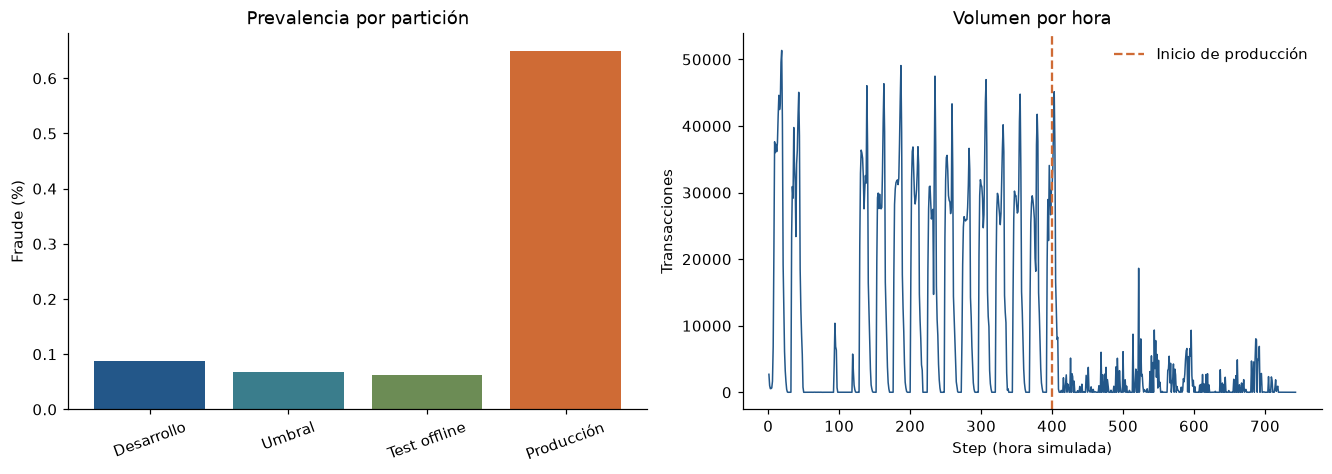

In [9]:
by_step = pd.read_csv(ROOT / 'reports/profile_by_step.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
labels = ['Desarrollo', 'Umbral', 'Test offline', 'Producción']
colors = ['#235789', '#3a7d8c', '#6c8c55', '#cf6b35']
axes[0].bar(labels, partitions.fraud_rate * 100, color=colors)
axes[0].set(ylabel='Fraude (%)', title='Prevalencia por partición')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].plot(by_step.step, by_step.rows, color='#235789', linewidth=1)
axes[1].axvline(400.5, color='#cf6b35', linestyle='--', label='Inicio de producción')
axes[1].set(xlabel='Step (hora simulada)', ylabel='Transacciones', title='Volumen por hora')
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.savefig(ROOT / 'reports/data_overview.png', dpi=160, bbox_inches='tight')
plt.show()

In [10]:
reference_rows = partitions.loc[['development', 'threshold_validation', 'offline_test'], 'rows'].sum()
reference_frauds = partitions.loc[['development', 'threshold_validation', 'offline_test'], 'frauds'].sum()
reference_rate = reference_frauds / reference_rows
production_rate = partitions.loc['production', 'fraud_rate']
display(Markdown(f'''**Resultados descriptivos:** {profile['rows']:,} transacciones y {profile['frauds']:,} fraudes.

La prevalencia pasa de **{reference_rate:.5%}** en referencia a **{production_rate:.5%}** en producción
({production_rate / reference_rate:.2f} veces). El último step observado es **{int(partitions.step_max.max())}**.

Esta diferencia exige reportar precision y recall junto con una curva PR y Average Precision. Accuracy por sí sola no será el criterio de elección.
'''))

**Resultados descriptivos:** 6,362,620 transacciones y 8,213 fraudes.

La prevalencia pasa de **0.07736%** en referencia a **0.64907%** en producción
(8.39 veces). El último step observado es **743**.

Esta diferencia exige reportar precision y recall junto con una curva PR y Average Precision. Accuracy por sí sola no será el criterio de elección.


## 7. Trazabilidad y MLflow

La conexión remota solo se declara verificada si se registra efectivamente el run en DagsHub. En ausencia de credenciales se usa el backend local explícitamente seleccionado. Este run registra preparación de datos, **no un modelo entrenado**.

In [11]:
display(configuration_status(ROOT))
tracking = log_preparation(ROOT)
display(tracking)
packages = ['pandas', 'numpy', 'pyarrow', 'scikit-learn', 'matplotlib', 'mlflow',
            'python-dotenv', 'ipykernel', 'nbformat', 'nbclient', 'nbconvert']
environment = {'python': sys.version.split()[0],
               'packages': {p: importlib.metadata.version(p) for p in packages}}
(ROOT / 'reports/environment-stage1.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print('Run real de preparación:', tracking['run_id'])

{'backend': 'local',
 'remote_config_present': {'MLFLOW_TRACKING_URI': False,
  'MLFLOW_TRACKING_USERNAME': False,
  'MLFLOW_TRACKING_PASSWORD': False},
 'remote_ready_to_attempt': False,
 'remote_connection_verified': False}

2026/10/15 19:02:35 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\katsu\Documents\Codex\2026-10-15\buenas-tardes-sres-les-adjunto-el\work\venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/15 19:02:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/15 19:02:37 INFO mlflow.store.db.utils: Updating database tables


{'run_id': '006f20c88daf4cb0bc76c561d414c77a',
 'experiment_name': 'fraud-data-preparation',
 'experiment_id': '1',
 'backend': 'local',
 'remote_connection_verified': False,
 'stage': 'data_preparation',
 'training_performed': False}

Run real de preparación: 006f20c88daf4cb0bc76c561d414c77a


## 8. Conclusiones

1. El archivo se conserva completo y se prepara en cuatro particiones verificadas, con trazabilidad del original y los Parquet.
2. Los identificadores, el target, la alerta existente, row_id y step están excluidos del contrato de predictores.
3. Los saldos finales limitan el caso a detección posterior a la transacción; un modelo preventivo requeriría otro contrato de variables.
4. El ratio indefinido y los saldos no informados de merchants requieren tratamiento explícito en entrenamiento.
5. Se han definido folds cronológicos con ambas clases. Ningún transformador se ha ajustado y no hay métricas de modelo todavía.
6. La siguiente etapa implementará un baseline y su evaluación temporal; después se compararán Random Search y Optuna/TPE.

**Fuentes:** consigna `Proyecto Final - Curso MLE3.pdf`, pp. 2 y 4–5; dataset PaySim entregado por el profesor; sesiones 1 (métricas), 3 (validación), 9–10 (producción y monitoreo). Código de tracking adaptado del patrón de la V2 del [repositorio anterior](https://github.com/jorgesialer/Proyecto-mle-riesgo).

Este HTML es evidencia de preparación exploratoria; el reporte final de monitoreo se desarrollará en otra etapa.